# Анализ ДТП — участник №3
**Датасет:** STATS19 Collisions. **Цель:** проверить три гипотезы, выполнить регрессионный и корреляционный анализ, обучить модель классификации и создать дашборд.

Используются Pandas, NumPy, Matplotlib и Scikit-learn, а также встроенные модули Python. Исходный CSV не изменяется. Предполагается одна строка на ДТП: ETL должен обеспечить уникальность `collision_index`.

- H1: доля тяжёлых и смертельных ДТП на дорогах с лимитом 50–70 mph выше, чем с лимитом 20–30 mph.
- H2: доля тяжёлых и смертельных ДТП в темноте без уличного освещения выше, чем при дневном свете.
- H3: в часы пик (07–10 и 16–19) зарегистрировано больше ДТП за час, чем в остальные часы.

Нулевые гипотезы: соответствующие доли/средние равны (для направленного теста нулевая область также включает отсутствие увеличения). Уровень значимости 0,05. Источник кодов: https://www.gov.uk/government/statistical-data-sets/road-safety-open-data .

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from pathlib import Path
from math import erfc, sqrt

FILE = Path('dft-road-casualty-statistics-collision-1979-latest-published-year.csv')
START_YEAR = 2022
END_YEAR = 2024
CHUNK_SIZE = 100_000
ALPHA = 0.05
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

if not FILE.exists():
    raise FileNotFoundError(f'Поместите CSV рядом с ноутбуком: {FILE.resolve()}')

## 1. Загрузка данных и контроль качества
Читаем только нужные столбцы блоками. Считаем годовую статистику по всему CSV. Для гипотез сохраняем только 2022–2024 гг. — это уменьшает расход памяти и ограничивает смешивание разных исторических периодов. Даже в этом периоде остаются различия в учёте тяжести. Проверяем идентификаторы в выбранном периоде; общая годовая статистика предполагает, что ETL уже удалил дубликаты. Неизвестные значения исключаются только из соответствующих расчётов.

In [2]:
columns = ['collision_index', 'collision_year', 'collision_severity',
           'speed_limit', 'light_conditions', 'date', 'time', 'police_force']
parts = []
annual_parts = []
rows = 0

for chunk in pd.read_csv(FILE, usecols=columns, chunksize=CHUNK_SIZE,
                         dtype={'collision_index': 'string', 'date': 'string', 'time': 'string'}):
    rows += len(chunk)
    chunk['collision_year'] = pd.to_numeric(chunk['collision_year'], errors='coerce')
    annual_parts.append(chunk['collision_year'].value_counts())
    selected = chunk[chunk['collision_year'].between(START_YEAR, END_YEAR)].copy()
    if not selected.empty:
        parts.append(selected)

annual = (pd.concat(annual_parts).groupby(level=0).sum().sort_index()
          .rename('collision_count').rename_axis('year').reset_index())
annual.to_csv(RESULTS / 'annual.csv', index=False)
if not parts:
    raise ValueError('В файле нет записей за выбранный период.')
df = pd.concat(parts, ignore_index=True)
del parts, annual_parts

if df['collision_index'].isna().any() or df['collision_index'].str.strip().eq('').any():
    raise ValueError('Есть пустые идентификаторы ДТП. Верните данные на ETL.')
if df['collision_index'].duplicated().any():
    raise ValueError('Есть повторяющиеся идентификаторы ДТП. Удалите дубликаты на ETL.')

for col in ['collision_severity', 'speed_limit', 'light_conditions', 'police_force']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['severe'] = np.where(df['collision_severity'].isin([1, 2]), 1,
                       np.where(df['collision_severity'].eq(3), 0, np.nan))
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y', errors='coerce')
valid_time = df['time'].str.fullmatch(r'(?:[01]\d|2[0-3]):[0-5]\d').fillna(False)
df['hour'] = pd.to_numeric(df['time'].where(valid_time).str[:2], errors='coerce')
valid_date = df['date'].dt.year.eq(df['collision_year'])
df['date'] = df['date'].where(valid_date)

quality = pd.DataFrame({'metric': ['rows_in_file', 'rows_in_period', 'unknown_severity',
                                   'unknown_or_other_speed', 'unknown_or_other_light', 'invalid_date_or_time'],
                        'value': [rows, len(df), df['severe'].isna().sum(),
                                  (~df['speed_limit'].isin([20,30,40,50,60,70])).sum(),
                                  (~df['light_conditions'].isin([1,4,5,6,7])).sum(),
                                  (df['date'].isna() | df['hour'].isna()).sum()]})
print(quality.to_string(index=False))
quality.to_csv(RESULTS / 'quality.csv', index=False)

                metric   value
          rows_in_file 9116625
        rows_in_period  311189
      unknown_severity       0
unknown_or_other_speed       3
unknown_or_other_light       7
  invalid_date_or_time       0


## 2. Проверка H1 и H2 — сравнение двух долей
Используем односторонний Z-тест двух пропорций. Доля = число тяжёлых/смертельных ДТП / число ДТП с известной тяжестью в группе. Z-статистика рассчитывается по объединённой доле. `erfc` — встроенная математическая функция Python для получения p-value нормального распределения; новая сторонняя библиотека не требуется. Если в группах слишком мало наблюдений, тест останавливается. Разницу выводим в процентных пунктах.

In [3]:
def compare_shares(data, mask1, mask0, name, label1, label0):
    a = data.loc[mask1, 'severe'].dropna()
    b = data.loc[mask0, 'severe'].dropna()
    n1, n0 = len(a), len(b)
    if min(n1, n0) == 0:
        raise ValueError(f'{name}: одна из групп пуста')
    x1, x0 = int(a.sum()), int(b.sum())
    if min(x1, n1-x1, x0, n0-x0) < 5:
        raise ValueError(f'{name}: слишком мало наблюдений для Z-теста')
    p1, p0 = x1/n1, x0/n0
    pooled = (x1+x0)/(n1+n0)
    se = np.sqrt(pooled*(1-pooled)*(1/n1+1/n0))
    z = (p1-p0)/se
    p_value = 0.5 * erfc(z/sqrt(2))
    table = pd.DataFrame({'group': [label1, label0], 'total': [n1,n0],
                          'severe_count': [x1,x0], 'severe_percent': [100*p1,100*p0]})
    result = {'hypothesis': name, 'group1': label1, 'group0': label0,
              'value1': 100*p1, 'value0': 100*p0, 'difference': 100*(p1-p0),
              'unit': 'percentage points', 'z': z, 'p_value': p_value}
    return table, result

speed_table, h1 = compare_shares(df, df['speed_limit'].isin([50,60,70]),
                                df['speed_limit'].isin([20,30]), 'H1', '50–70 mph', '20–30 mph')
print(speed_table.to_string(index=False))
speed_table.to_csv(RESULTS / 'speed.csv', index=False)

light_table, h2 = compare_shares(df, df['light_conditions'].eq(6),
                                df['light_conditions'].eq(1), 'H2', 'Без освещения', 'Дневной свет')
print(light_table.to_string(index=False))
light_table.to_csv(RESULTS / 'light.csv', index=False)

    group  total  severe_count  severe_percent
50–70 mph  68883         21176       30.741983
20–30 mph 215038         46723       21.727788
        group  total  severe_count  severe_percent
Без освещения  16878          5854       34.684204
 Дневной свет 221752         51177       23.078484


## 3. Проверка H3 — часы пик
Для каждого календарного дня считаем ДТП за час в двух периодах (6 часов пик, 18 остальных). Сравниваем парные разности по дням. Используем нормальное приближение для среднего парных разностей (не точный t-тест); оно требует достаточно дней и приблизительной независимости разностей. Временная зависимость может влиять на p-value. Все дни должны присутствовать в выборке с корректным временем, иначе тест не выполняется: нельзя считать отсутствующие данные нулём. Период включает будни и выходные.

In [4]:
timed = df.dropna(subset=['date', 'hour']).copy()
timed['hour'] = timed['hour'].astype(int)
timed['peak'] = timed['hour'].isin([7,8,9,16,17,18])
calendar = pd.date_range(f'{START_YEAR}-01-01', f'{END_YEAR}-12-31', freq='D')
if len(calendar.difference(timed['date'].unique())):
    raise ValueError('Не все дни периода представлены корректными датами/временем. Проверьте полноту данных или выберите полные годы.')

daily = (timed.groupby(['date','peak']).size().unstack(fill_value=0)
         .reindex(index=calendar, columns=[True,False], fill_value=0))
daily.columns = ['peak_count', 'other_count']
daily.index.name = 'date'
daily['peak_per_hour'] = daily['peak_count']/6
daily['other_per_hour'] = daily['other_count']/18
daily['difference'] = daily['peak_per_hour']-daily['other_per_hour']
d = daily['difference']
if len(d) < 30 or d.std(ddof=1) == 0:
    raise ValueError('Недостаточно вариации или дней для нормального приближения.')
z3 = d.mean()/(d.std(ddof=1)/np.sqrt(len(d)))
h3 = {'hypothesis': 'H3', 'group1': 'Часы пик', 'group0': 'Другие часы',
      'value1': daily['peak_per_hour'].mean(), 'value0': daily['other_per_hour'].mean(),
      'difference': d.mean(), 'unit': 'collisions/hour', 'z': z3,
      'p_value': 0.5*erfc(z3/sqrt(2))}
print(daily[['peak_per_hour','other_per_hour']].mean())
daily.to_csv(RESULTS / 'daily.csv')
hourly = timed.groupby('hour').size().reindex(range(24), fill_value=0).rename('collision_count')
hourly.to_csv(RESULTS / 'hourly.csv')
heatmap = (timed.groupby([timed['date'].dt.dayofweek.rename('weekday'), 'hour']).size()
           .unstack(fill_value=0).reindex(index=range(7), columns=range(24), fill_value=0))
heatmap.to_csv(RESULTS / 'heatmap.csv')

peak_per_hour     18.405414
other_per_hour     9.638838
dtype: float64


## 4. Итоги статистических тестов
Поправка Бонферрони для трёх проверок: умножаем p-value на 3 (не более 1). Если скорректированное p-value < 0,05 — отклоняем H0 в пользу направленной H1. Иначе недостаточно оснований отклонить H0. Учитывайте величину разницы, а не только значимость. Тесты являются приближёнными; пространственная и временная зависимость наблюдений может завышать значимость.

In [5]:
hypotheses = pd.DataFrame([h1,h2,h3])
hypotheses['p_adjusted'] = np.minimum(hypotheses['p_value']*len(hypotheses), 1)
hypotheses['decision'] = np.where(hypotheses['p_adjusted'] < ALPHA,
                                  'Отклоняем H0', 'Недостаточно оснований отклонить H0')
print(hypotheses.to_string(index=False))
hypotheses.to_csv(RESULTS / 'hypotheses.csv', index=False)

hypothesis        group1       group0    value1    value0  difference              unit         z       p_value    p_adjusted     decision
        H1     50–70 mph    20–30 mph 30.741983 21.727788    9.014195 percentage points 48.267929  0.000000e+00  0.000000e+00 Отклоняем H0
        H2 Без освещения Дневной свет 34.684204 23.078484   11.605720 percentage points 34.081340 6.971175e-255 2.091352e-254 Отклоняем H0
        H3      Часы пик  Другие часы 18.405414  9.638838    8.766575   collisions/hour 49.044365  0.000000e+00  0.000000e+00 Отклоняем H0


## 5. Логистическая регрессия (Scikit-learn)
Целевая переменная — тяжёлое/смертельное ДТП (1) либо лёгкое (0). Сравниваем те же группы скорости и света; дополнительно учитываем год и полицейское подразделение. Оставляем только наблюдения с известными значениями всех признаков. `exp(коэффициент)` — отношение шансов при прочих включённых признаках, а не изменение вероятности и не причинный эффект. Модель с обычной L2-регуляризацией используется для описания связи, не для статистических p-value и не для оценки прогнозной точности.

In [6]:
model_data = df[df['speed_limit'].isin([20,30,50,60,70]) &
                df['light_conditions'].isin([1,6]) & df['severe'].notna() &
                df['police_force'].gt(0)].copy()
model_data['high_speed'] = model_data['speed_limit'].isin([50,60,70]).astype(int)
model_data['no_lighting'] = model_data['light_conditions'].eq(6).astype(int)
X = pd.get_dummies(model_data[['high_speed','no_lighting','collision_year','police_force']],
                   columns=['collision_year','police_force'], drop_first=True, dtype=int)
y = model_data['severe'].astype(int)
if y.nunique() != 2 or X['high_speed'].nunique() != 2 or X['no_lighting'].nunique() != 2:
    raise ValueError('Недостаточно различных наблюдений для регрессии.')
model = LogisticRegression(max_iter=1000)
model.fit(X,y)
regression = pd.DataFrame({'feature': X.columns, 'coefficient': model.coef_[0],
                           'odds_ratio': np.exp(model.coef_[0])})
regression.to_csv(RESULTS / 'regression.csv', index=False)
print('Количество наблюдений:', len(y))
print(regression.head(2).to_string(index=False))

Количество наблюдений: 217794
    feature  coefficient  odds_ratio
 high_speed     0.384391    1.468720
no_lighting     0.264145    1.302316


## 6. Визуализация результатов
Четыре графика по гипотезам и один исторический. В дашборд передаются CSV-таблицы. Временная статистика не является риском ДТП на одну поездку: нет данных об интенсивности движения.

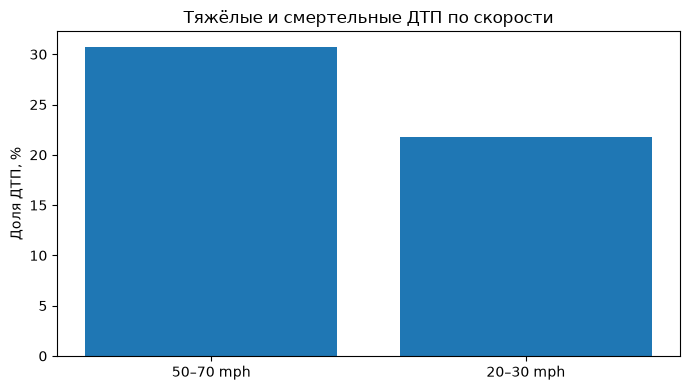

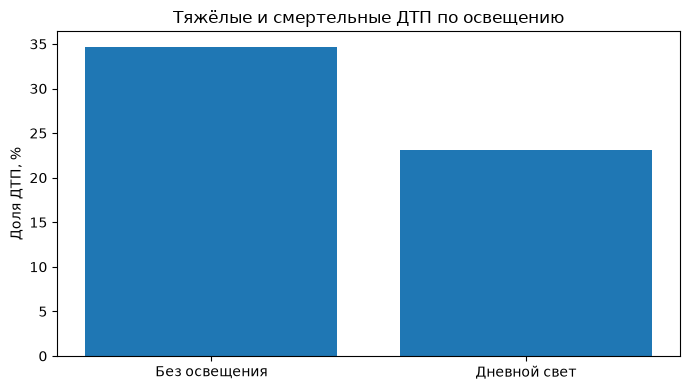

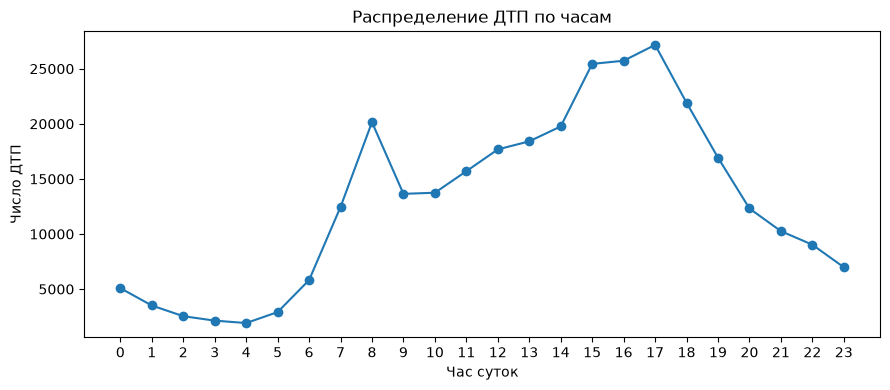

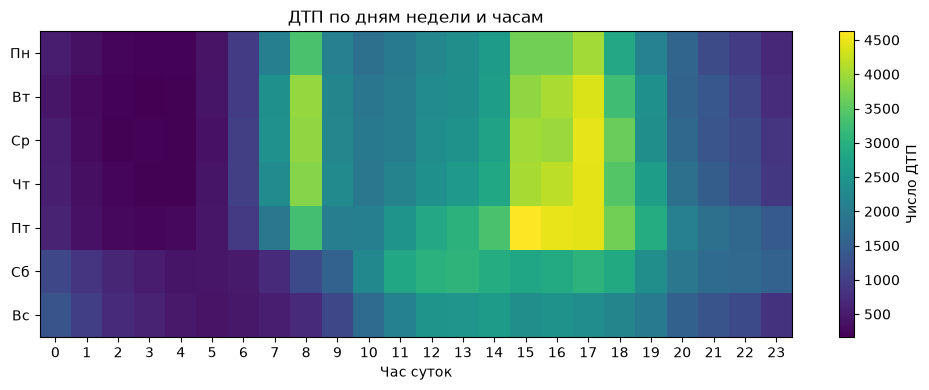

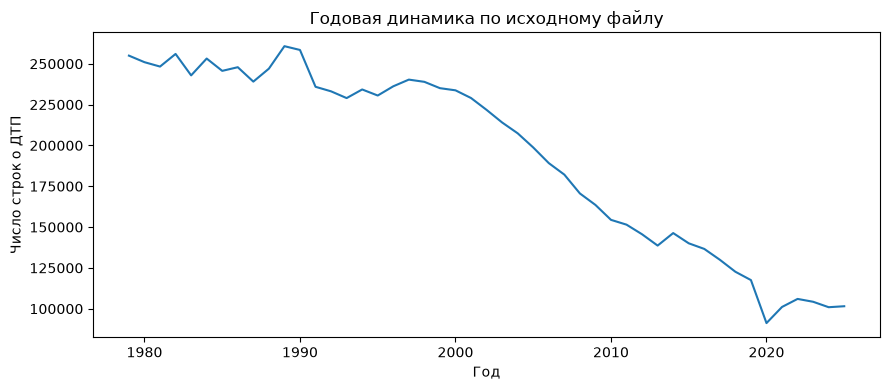

Результаты сохранены: C:\Users\user\PycharmProjects\PythonProject\Архитектура больших данных\results


In [7]:
def save_plot(filename):
    plt.tight_layout()
    plt.savefig(RESULTS / filename, dpi=150)
    plt.show()
    plt.close()

for table, name, title in [(speed_table, 'speed.png', 'Тяжёлые и смертельные ДТП по скорости'),
                           (light_table, 'light.png', 'Тяжёлые и смертельные ДТП по освещению')]:
    plt.figure(figsize=(7,4))
    plt.bar(table['group'], table['severe_percent'])
    plt.ylabel('Доля ДТП, %')
    plt.title(title)
    save_plot(name)

plt.figure(figsize=(9,4))
plt.plot(hourly.index, hourly.values, marker='o')
plt.xticks(range(24))
plt.xlabel('Час суток')
plt.ylabel('Число ДТП')
plt.title('Распределение ДТП по часам')
save_plot('hourly.png')

plt.figure(figsize=(10,4))
plt.imshow(heatmap.values, aspect='auto')
plt.yticks(range(7), ['Пн','Вт','Ср','Чт','Пт','Сб','Вс'])
plt.xticks(range(24))
plt.xlabel('Час суток')
plt.colorbar(label='Число ДТП')
plt.title('ДТП по дням недели и часам')
save_plot('heatmap.png')

plt.figure(figsize=(9,4))
plt.plot(annual['year'], annual['collision_count'])
plt.xlabel('Год')
plt.ylabel('Число строк о ДТП')
plt.title('Годовая динамика по исходному файлу')
save_plot('annual.png')
print('Результаты сохранены:', RESULTS.resolve())

## 7. Корреляционный анализ
Рассчитаем коэффициент корреляции Пирсона между ограничением скорости, отсутствием освещения, часами пик и тяжестью ДТП. Для освещения сравниваем только дневной свет (0) и темноту без уличного освещения (1). Остальные признаки: час пик (1/0), тяжёлое или смертельное ДТП (1/0). Используем строки с известными значениями всех четырёх признаков.

Коэффициент изменяется от −1 до +1. Знак показывает направление линейной связи, а модуль — её силу. Корреляция не доказывает причинность. Для бинарных признаков коэффициент Пирсона также применим. Числовые коды категорий освещения напрямую не коррелируем.

Записей для корреляционного анализа: 238628
             speed_limit  no_lighting   peak  severe
speed_limit        1.000        0.316 -0.029   0.102
no_lighting        0.316        1.000 -0.085   0.070
peak              -0.029       -0.085  1.000  -0.029
severe             0.102        0.070 -0.029   1.000


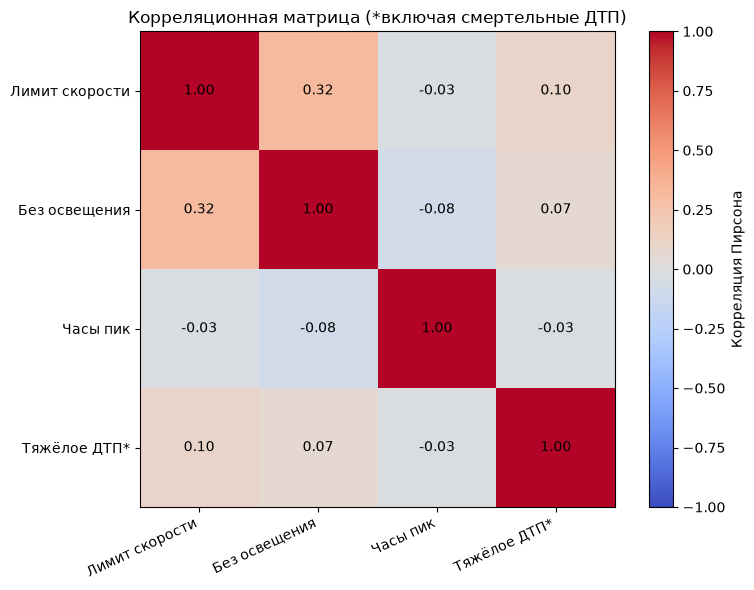

In [8]:
corr_data = df.loc[
    df['speed_limit'].isin([20, 30, 40, 50, 60, 70]) &
    df['light_conditions'].isin([1, 6]) &
    df['severe'].notna() & df['hour'].notna() & df['date'].notna()
].copy()

corr_data['no_lighting'] = corr_data['light_conditions'].eq(6).astype(int)
corr_data['peak'] = corr_data['hour'].isin([7, 8, 9, 16, 17, 18]).astype(int)
correlation = corr_data[['speed_limit', 'no_lighting', 'peak', 'severe']].corr()
print('Записей для корреляционного анализа:', len(corr_data))
print(correlation.round(3))
correlation.to_csv(RESULTS / 'correlation.csv')

labels = ['Лимит скорости', 'Без освещения', 'Часы пик', 'Тяжёлое ДТП*']
plt.figure(figsize=(8, 6))
plt.imshow(correlation.values, cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(range(4), labels, rotation=25, ha='right')
plt.yticks(range(4), labels)
for i in range(4):
    for j in range(4):
        plt.text(j, i, f'{correlation.iloc[i, j]:.2f}', ha='center', va='center')
plt.colorbar(label='Корреляция Пирсона')
plt.title('Корреляционная матрица (*включая смертельные ДТП)')
save_plot('correlation.png')
del corr_data

## 8. Машинное обучение — случайный лес
Обучим одну модель `RandomForestClassifier`, чтобы классифицировать зарегистрированные ДТП: 0 — лёгкое, 1 — тяжёлое или смертельное. Входные признаки: лимит скорости, освещение, час суток и день недели. Освещение и день недели кодируем отдельными индикаторами, чтобы не задавать искусственный числовой порядок категорий. Тяжесть ДТП используется только как целевой признак.

Обучаем модель на 2022–2023 годах, проверяем на 2024 году (при изменении периода — на последнем году). Ограничиваем глубину деревьев и их количество для умеренного расхода памяти. `class_weight='balanced'` помогает учитывать более редкий класс тяжёлых ДТП. Для сравнения рассчитываем точность простого правила «всегда выбирать наиболее частый класс» на той же тестовой выборке.

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix)

ml_data = df.loc[
    df['speed_limit'].isin([20, 30, 40, 50, 60, 70]) &
    df['light_conditions'].isin([1, 4, 5, 6]) &
    df['severe'].notna() & df['hour'].notna() & df['date'].notna()
].copy()
ml_data['weekday'] = ml_data['date'].dt.dayofweek

features = ['speed_limit', 'light_conditions', 'hour', 'weekday']
train = ml_data[ml_data['collision_year'] < END_YEAR]
test = ml_data[ml_data['collision_year'] == END_YEAR]
X_train = pd.get_dummies(train[features], columns=['light_conditions', 'weekday'])
X_test = pd.get_dummies(test[features], columns=['light_conditions', 'weekday'])
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
y_train = train['severe'].astype(int)
y_test = test['severe'].astype(int)
if y_train.nunique() != 2 or y_test.nunique() != 2:
    raise ValueError('Для обучения и проверки нужны оба класса ДТП в разных годах.')

forest = RandomForestClassifier(n_estimators=40, max_depth=8,
                                class_weight='balanced', random_state=42, n_jobs=2)
forest.fit(X_train, y_train)
pred = forest.predict(X_test)
baseline = np.full(len(y_test), y_train.mode().iloc[0])

ml_metrics = pd.DataFrame([
    {'model': name, 'accuracy': accuracy_score(y_test, result),
     'balanced_accuracy': balanced_accuracy_score(y_test, result),
     'precision': precision_score(y_test, result, zero_division=0),
     'recall': recall_score(y_test, result, zero_division=0),
     'f1': f1_score(y_test, result, zero_division=0)}
    for name, result in [('Базовое правило', baseline), ('Случайный лес', pred)]
])
print('Обучающая выборка:', len(train), '| Тестовая выборка:', len(test))
print(ml_metrics.round(3).to_string(index=False))
ml_metrics.to_csv(RESULTS / 'ml_metrics.csv', index=False)

Обучающая выборка: 206916 | Тестовая выборка: 99239
          model  accuracy  balanced_accuracy  precision  recall    f1
Базовое правило     0.751              0.500      0.000   0.000 0.000
  Случайный лес     0.628              0.554      0.311   0.406 0.352


### Матрица ошибок
Accuracy — общая доля верных ответов; Balanced Accuracy — средняя полнота двух классов; Precision — доля действительно тяжёлых ДТП среди предсказанных тяжёлых; Recall — доля найденных тяжёлых ДТП; F1 — баланс Precision и Recall. Матрица ошибок показывает правильные и ошибочные предсказания по классам. Если модель не превосходит базовое правило по выбранной метрике, это тоже результат исследования. Модель оценивает тяжесть уже зарегистрированных ДТП, а не вероятность возникновения аварии.

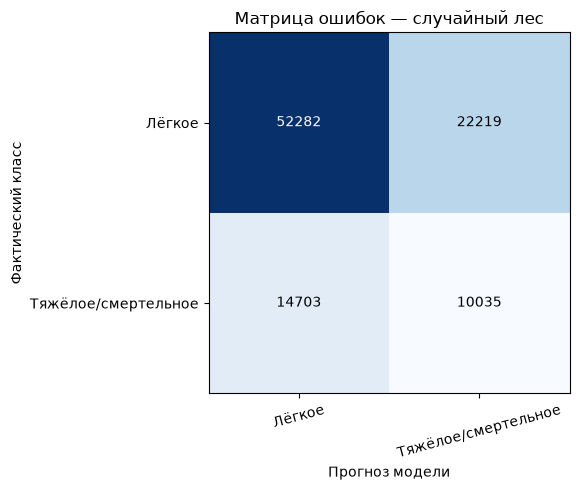

In [10]:
cm = confusion_matrix(y_test, pred, labels=[0, 1])
pd.DataFrame(cm, index=['Факт: лёгкое', 'Факт: тяжёлое/смертельное'],
             columns=['Прогноз: лёгкое', 'Прогноз: тяжёлое/смертельное']).to_csv(
                 RESULTS / 'ml_confusion.csv')
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.xticks([0, 1], ['Лёгкое', 'Тяжёлое/смертельное'], rotation=15)
plt.yticks([0, 1], ['Лёгкое', 'Тяжёлое/смертельное'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha='center', va='center',
                 color='white' if cm[i, j] > cm.max()/2 else 'black')
plt.xlabel('Прогноз модели')
plt.ylabel('Фактический класс')
plt.title('Матрица ошибок — случайный лес')
save_plot('ml_confusion.png')

## 9. Дашборд
Отдельный HTML-файл с общей статистикой, распределением ДТП по часам и сравнением тяжести ДТП по скорости и освещению. Фильтр позволяет выбрать год или весь период анализа; графики и KPI меняются одновременно. Результаты гипотез и машинного обучения показаны отдельно за фиксированный период. Никаких новых библиотек или сервера не требуется. После запуска откройте `results/dashboard.html` в браузере.

In [11]:
# Подготовка небольших HTML-графиков из уже обработанных данных.
def bars(labels, values, percent=False):
    maximum = 100 if percent else max(values, default=1)
    maximum = max(maximum, 1)
    rows = []
    for label, value in zip(labels, values):
        if pd.isna(value):
            rows.append(f'<div>{label}: нет данных</div>')
            continue
        text = f'{value:.2f}%' if percent else f'{value:,.0f}'.replace(',', ' ')
        rows.append(f'<div class="bar"><span>{label}</span>'
                    f'<i style="width:{100*value/maximum:.2f}%"></i><b>{text}</b></div>')
    return ''.join(rows)

def share(data, mask):
    return 100 * data.loc[mask, 'severe'].mean()

# Считаем показатели для каждого года и всего периода.
years = sorted(df['collision_year'].astype(int).unique())
panels = []
options = []
for key, label, data in [('all', f'{START_YEAR}–{END_YEAR}', df)] + [
    (str(year), str(year), df[df['collision_year'].eq(year)]) for year in years
]:
    options.append(f'<option value="{key}">{label}</option>')
    time_data = data.dropna(subset=['date', 'hour'])
    counts = time_data.groupby('hour').size().reindex(range(24), fill_value=0)
    severity = data['severe'].dropna()
    severe_percent = 100 * severity.mean()
    peak = counts.idxmax() if counts.sum() else None
    peak_label = f'{int(peak):02d}:00' if peak is not None else 'нет данных'
    severity_label = f'{severe_percent:.2f}%' if len(severity) else 'нет данных'
    total_label = f'{len(data):,}'.replace(',', ' ')
    high = share(data, data['speed_limit'].isin([50, 60, 70]))
    low = share(data, data['speed_limit'].isin([20, 30]))
    dark = share(data, data['light_conditions'].eq(6))
    daylight = share(data, data['light_conditions'].eq(1))
    panels.append(f'''<section id="p-{key}" {'hidden' if key != 'all' else ''}>
    <div class="kpis"><div>Записей о ДТП<strong>{total_label}</strong></div>
    <div>Тяжёлые и смертельные<strong>{severity_label}</strong></div>
    <div>Пиковый час<strong>{peak_label}</strong></div></div>
    <h2>ДТП по часам</h2>{bars([f'{h:02d}:00' for h in range(24)], counts.tolist())}
    <h2>Доля тяжёлых и смертельных ДТП по скорости</h2>
    {bars(['50–70 mph', '20–30 mph'], [high, low], True)}
    <h2>Доля тяжёлых и смертельных ДТП по освещению</h2>
    {bars(['Без света', 'Дневной свет'], [dark, daylight], True)}</section>''')

html = '''<!doctype html><html lang="ru"><meta charset="utf-8">
<title>Road Safety Analytics</title><style>
body{font:16px Arial,sans-serif;max-width:960px;margin:32px auto;padding:0 16px;color:#18334b;background:#f6f8fb}
h1,h2{margin:24px 0 12px}h2{font-size:20px}select{padding:8px;font:inherit}
.kpis{display:flex;gap:12px;flex-wrap:wrap;margin:20px 0}.kpis div{background:white;border:1px solid #d6e0ea;padding:16px;flex:1;min-width:130px}
strong{display:block;font-size:26px;margin-top:8px}.bar{display:grid;grid-template-columns:115px minmax(100px,1fr) 85px;align-items:center;gap:8px;margin:5px 0}
.bar i{display:block;height:15px;background:#3978ae}.bar b{text-align:right;font-size:13px}
table{border-collapse:collapse;width:100%;background:white;font-size:14px}td,th{border:1px solid #d6e0ea;padding:8px;text-align:left}small{color:#526578}
</style><h1>Road Safety Analytics</h1><p>Анализ ДТП в Великобритании</p>
<label>Период: <select id="year" onchange="changeYear()">''' + ''.join(options) + '''</select></label>''' + ''.join(panels)
html += f'<h2>Проверка гипотез ({START_YEAR}–{END_YEAR})</h2>'
html += hypotheses[['hypothesis', 'value1', 'value0', 'unit', 'decision']].round(3).to_html(index=False)
html += f'<h2>Машинное обучение (тест: {END_YEAR})</h2>' + ml_metrics.round(3).to_html(index=False)
html += '''<p><small>Таблицы гипотез и модели не меняются при выборе года. Доли рассчитаны среди ДТП с известной тяжестью. Количество ДТП не равно риску на одну поездку.</small></p>
<script>function changeYear(){document.querySelectorAll('section').forEach(p=>p.hidden=p.id!=='p-'+document.getElementById('year').value);}</script></html>'''
(RESULTS / 'dashboard.html').write_text(html, encoding='utf-8')
print('Дашборд сохранён:', (RESULTS / 'dashboard.html').resolve())

Дашборд сохранён: C:\Users\user\PycharmProjects\PythonProject\Архитектура больших данных\results\dashboard.html


## 10. Выводы
После запуска используйте `hypotheses.csv` для формулировки выводов: сравните значения групп, разницу, скорректированное p-value и направление эффекта. Не пишите о подтверждённых причинных связях. STATS19 учитывает зарегистрированные полицией ДТП с пострадавшими на дорогах общего пользования; изменения полноты и методики регистрации ограничивают исторические сравнения. Ограничение скорости не является фактической скоростью автомобиля. После повторного запуска дополните выводы по корреляционной матрице и метрикам случайного леса. Сравните модель с базовым правилом; оцените не только Accuracy, но и Balanced Accuracy и Recall. Новые результаты сохраняются в папке results, интерактивный дашборд — в dashboard.html.